In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

pd.set_option('display.max_columns', None)

In [2]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('playground-series-s6e10')

print("Path to competition files:", path)

Path to competition files: /home/thoughtstorm06/.cache/kagglehub/competitions/playground-series-s6e10


In [3]:
df = pd.read_csv(path+'/train.csv')
df.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [4]:
df.shape
df['satisfaction'].value_counts()

satisfaction
False    389296
True     310339
Name: count, dtype: int64

In [5]:
y = df['satisfaction']
X = df.drop(columns=['satisfaction'])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    shuffle=True,
    random_state=42,
    stratify=y
)

df = pd.concat([X_train, y_train], axis=1)

In [6]:
df.isnull().sum()
df.info()
df.describe()

<class 'pandas.DataFrame'>
Index: 559708 entries, 159366 to 241208
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 559708 non-null  int64  
 1   Age                                559708 non-null  int64  
 2   Flight Distance                    559708 non-null  int64  
 3   Inflight wifi service              559708 non-null  int64  
 4   Departure/Arrival time convenient  559708 non-null  int64  
 5   Ease of Online booking             559708 non-null  int64  
 6   Gate location                      559708 non-null  int64  
 7   Food and drink                     559708 non-null  int64  
 8   Online boarding                    559708 non-null  int64  
 9   Seat comfort                       559708 non-null  int64  
 10  Inflight entertainment             559708 non-null  int64  
 11  On-board service                   559708 non-null

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,559708.000000,559708.000000,559708.000000,559708.000000,559708.000000,559708.000000,559708.000000,559708.000000,559708.000000,559708.000000,559708.000000,559708.000000,559708.000000,559708.000000,559708.000000,559708.000000,559708.00000,559481.000000
mean,349936.725430,39.004856,1353.909553,2.778813,3.156246,2.813313,3.013814,3.266091,3.364697,3.569604,3.454337,3.516959,3.473627,3.805416,3.421505,3.381367,1.17591,1.132147
std,201941.535221,13.791322,954.736682,1.280669,1.474977,1.330029,1.254360,1.300522,1.288460,1.275440,1.308191,1.239235,1.271606,1.078950,1.210159,1.277767,5.96002,5.723220
min,0.000000,7.000000,67.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.00000,0.000000
25%,175097.750000,27.000000,631.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,2.000000,0.00000,0.000000
50%,349909.500000,40.000000,954.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,0.00000,0.000000
75%,525024.250000,50.000000,1814.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.000000,4.000000,0.00000,0.000000
max,699634.000000,85.000000,4983.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,489.00000,491.000000


## Numeric Features: Age, Flight Distance, Departure & Arrival Delay

**Correlation:** Departure and Arrival Delay are strongly linked (r = 0.84). Age and Flight Distance are weakly linked (r = 0.19). Every other pair is about 0, so these features are mostly independent.

### Age
- Mean 39.0, median 40, std 13.8, range 7-85.
- **Bimodal:** peaks at about 25 (17,894) and about 39 (17,643), with a dip around 31-34.
- Sharp drops at 60→61 (8,398 → 3,347) and 70→71 (1,911 → 76). Very few passengers are above 71.
- **Contribution:** satisfaction depends on age and the relationship is non-linear. Ages 40-60 are mostly satisfied, and under 40 or over 60 are mostly dissatisfied. Disloyal customers cluster at about 20-30. Business travel creates the two peaks and the cutoff at 60, while personal travel is flat across ages.
- **Handling:** use age bands (e.g. <20, 20-39, 40-60, 60+) or a tree model, and merge the sparse 70+ tail into one group.

### Flight Distance
- Mean 1354, median 954, std 955, range 67-4,983.
- **Right-skewed and multimodal** (peaks near 600, 900, 1,600-1,800 and 2,500), which suggests short, regional and long-haul route types.
- Red dashed `axvline` = **Q3 = 1814**. 75% of flights are shorter than this.
- IQR bounds are -1143.5 to 3588.5. There are no low outliers, and **18,331 rows (about 3.3%)** sit above the upper bound. These are real long-haul flights, not errors.
- **Satisfaction:** the spread is too wide and uneven (std about 955, several peaks) to relate to satisfaction from the histogram alone.
- **Handling:** apply `log1p` or cap at the upper bound for linear models, or create distance bands. Trees need neither.

### Departure & Arrival Delay
- Both are **extremely right-skewed and zero-inflated:** median and Q3 are 0, mean about 1.2, std about 6, max about 490 min.
- IQR = 0, so the IQR rule flags every delayed flight as an outlier and can't be used here.
- Arrival Delay has **227 missing values.**
- **Satisfaction:** almost all values sit at 0 with a few extreme delays, so the histogram can't show any relationship with satisfaction.
- **Handling:**
  - Impute missing Arrival Delay from Departure Delay (or 0).
  - Use `log1p`, or a `delayed` flag with delay bins (0 / 1-15 / 15-60 / 60+).
  - Because of the 0.84 correlation, keep one delay for linear models, or use `arrival - departure`.
  - Keep the extreme delays.

In [7]:
df.columns
df[['Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']].corr(method='pearson')

,Age,Flight Distance,Departure Delay in Minutes,Arrival Delay in Minutes
Age,1.000000,0.189870,-0.010341,-0.012400
Flight Distance,0.189870,1.000000,-0.006488,-0.012091
Departure Delay in Minutes,-0.010341,-0.006488,1.000000,0.840479
Arrival Delay in Minutes,-0.012400,-0.012091,0.840479,1.000000


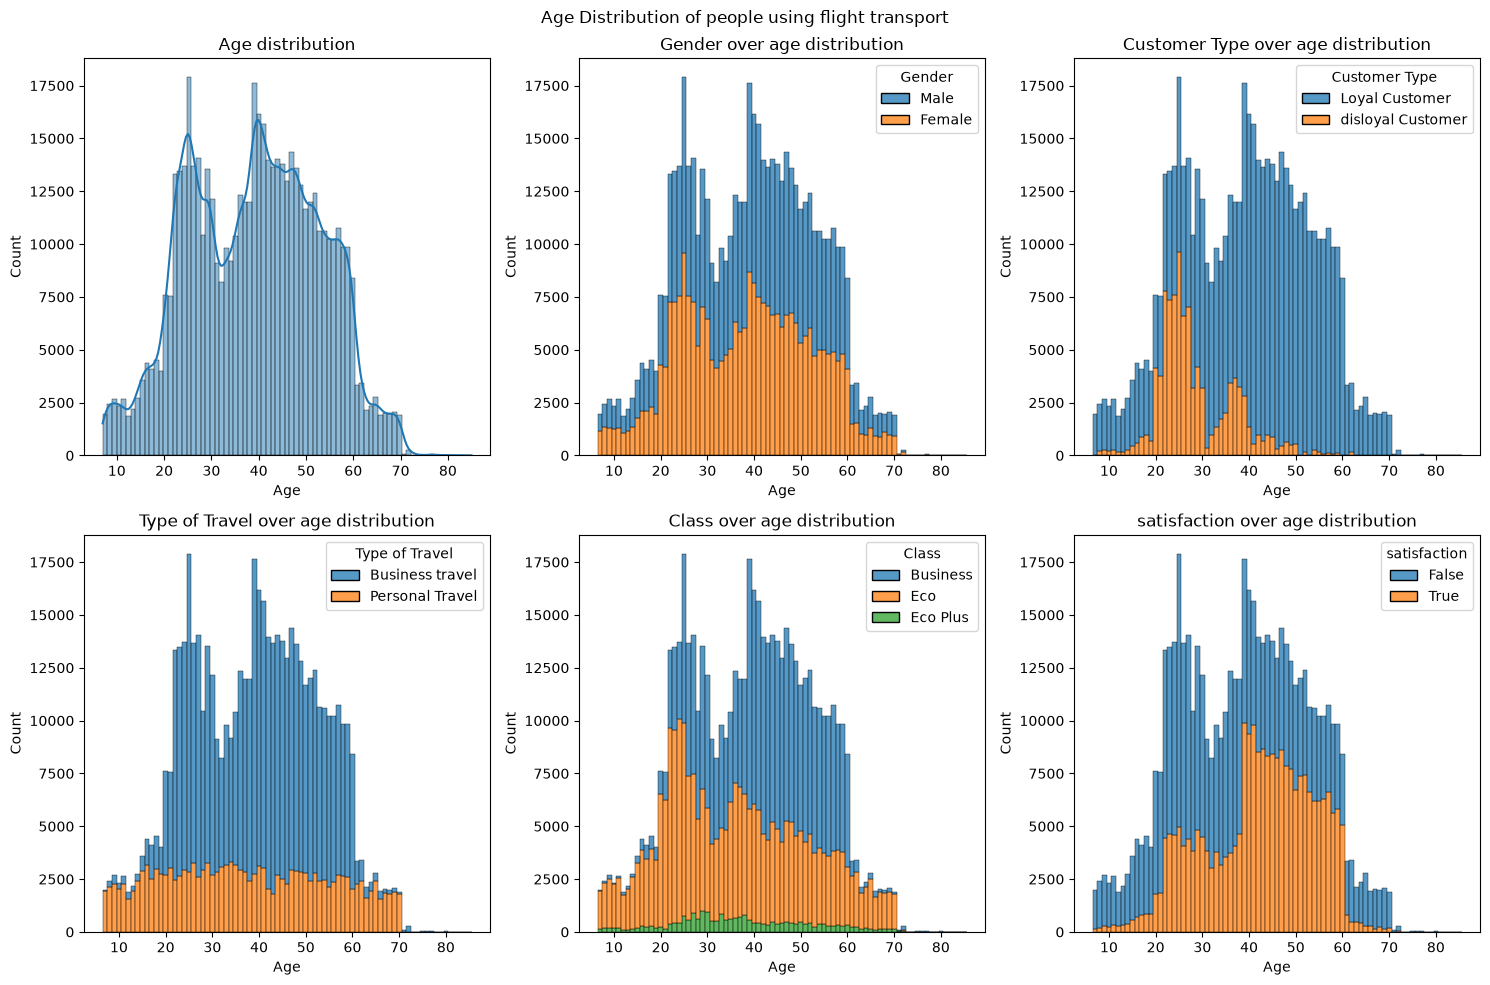

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
comparison_columns = ['Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction']

for i, ax in enumerate(axes.flatten()):
    if i == 0:
        sns.histplot(df['Age'], bins=79, kde=True, ax=ax)
        ax.set_title('Age distribution')
    else:
        sns.histplot(data=df, x='Age', hue=comparison_columns[i - 1], discrete=True, multiple='stack', ax=ax)
        ax.set_title(f'{comparison_columns[i - 1]} over age distribution')


plt.suptitle('Age Distribution of people using flight transport')
plt.tight_layout()
plt.show()

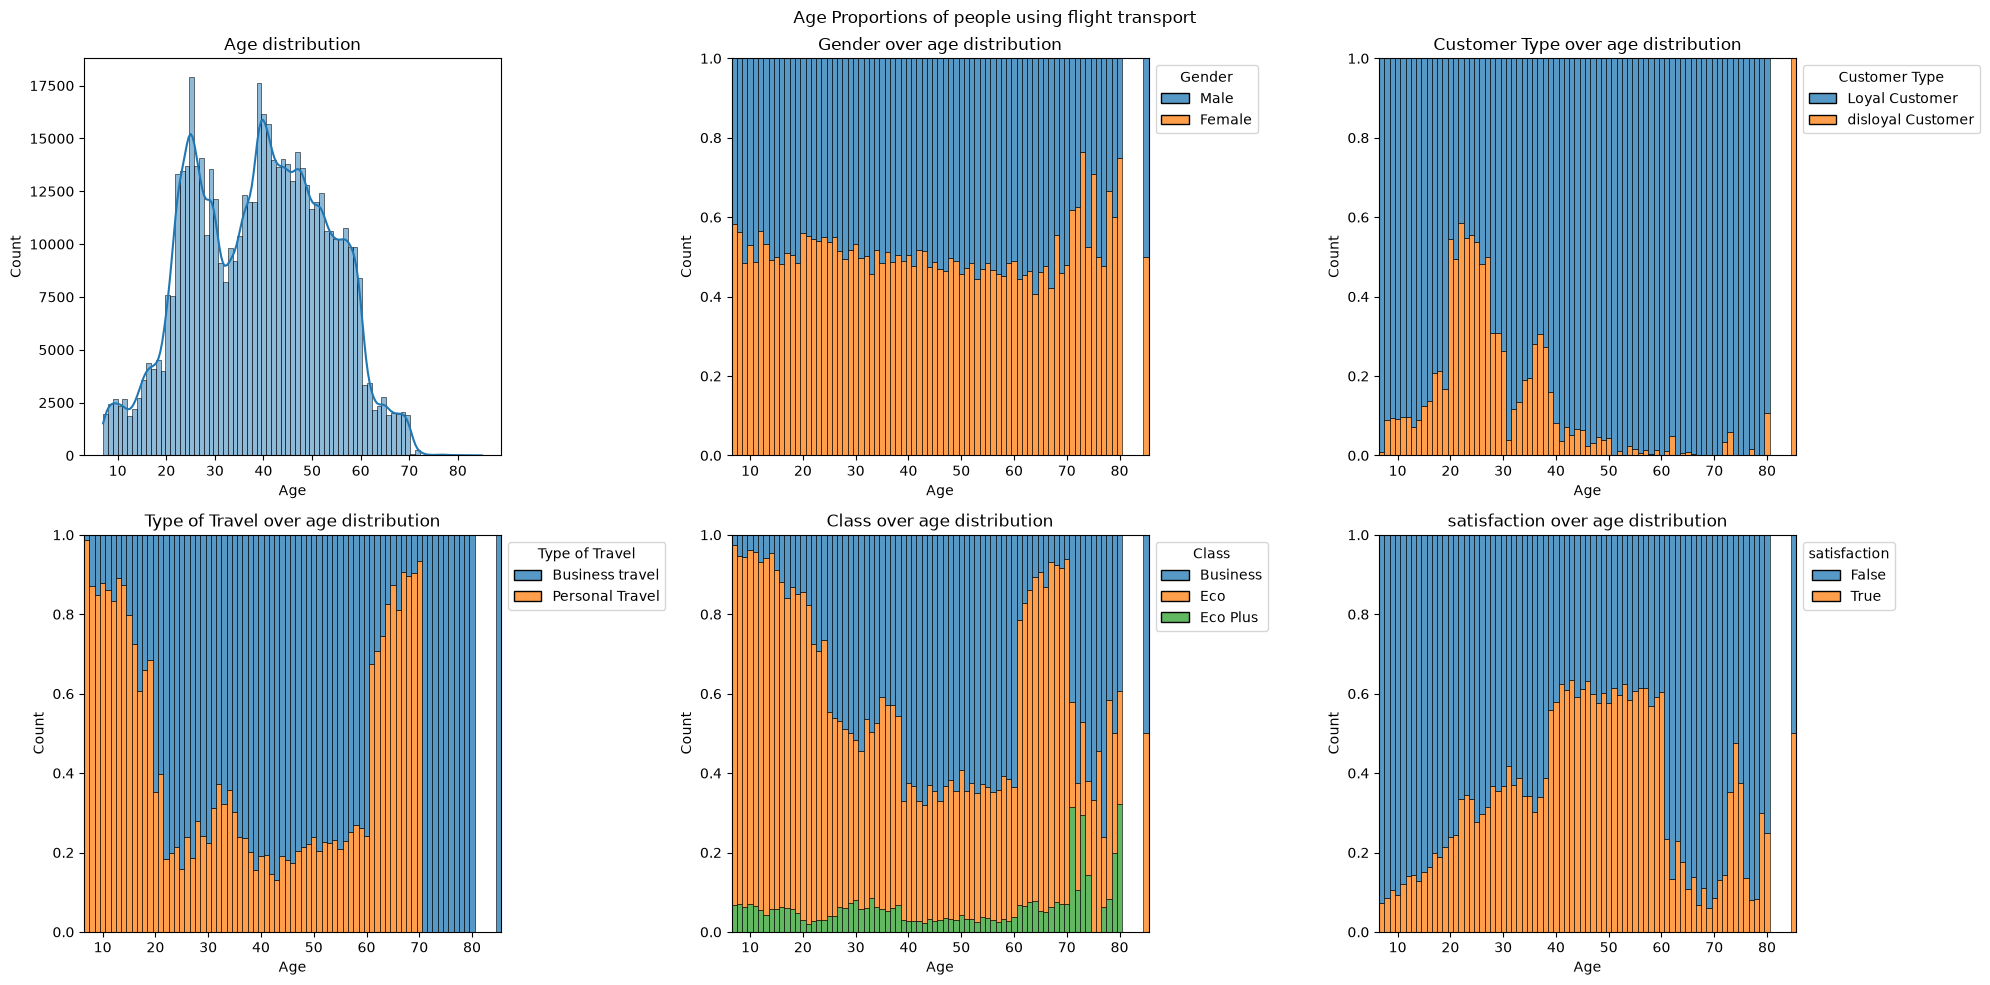

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
comparison_columns = ['Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction']

for i, ax in enumerate(axes.flatten()):
    if i == 0:
        sns.histplot(df['Age'], bins=79, kde=True, ax=ax)
        ax.set_title('Age distribution')
    else:
        sns.histplot(data=df, x='Age', hue=comparison_columns[i - 1], discrete=True, multiple='fill', ax=ax)
        ax.set_title(f'{comparison_columns[i - 1]} over age distribution')
        sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))


plt.suptitle('Age Proportions of people using flight transport')
plt.tight_layout()
plt.show()

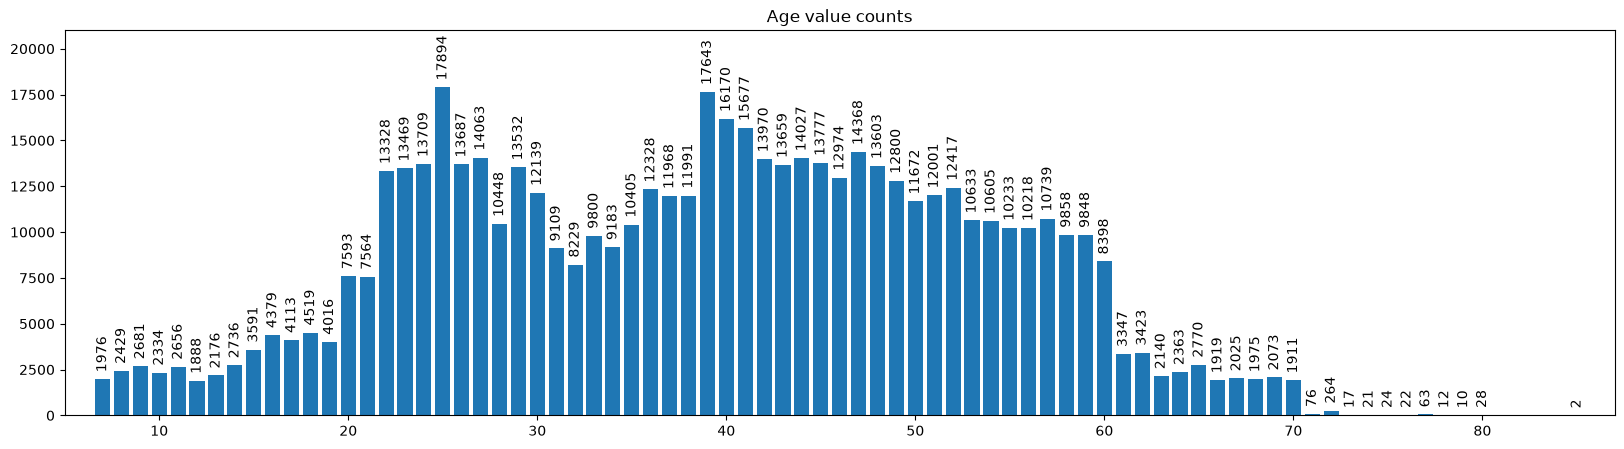

In [10]:
df['Age'].describe()
df['Age'].value_counts().sort_index().tail(20)

plt.figure(figsize=(20, 5))
bar = plt.bar(df['Age'].value_counts().index, df['Age'].value_counts())
plt.bar_label(bar, rotation=90, padding=5)
plt.xlim(5, 87)
plt.ylim(0, 21000)
plt.title('Age value counts')
plt.show()

Lower bound: -1143.5
Upper bound: 3588.5
Number of outliers: 18331


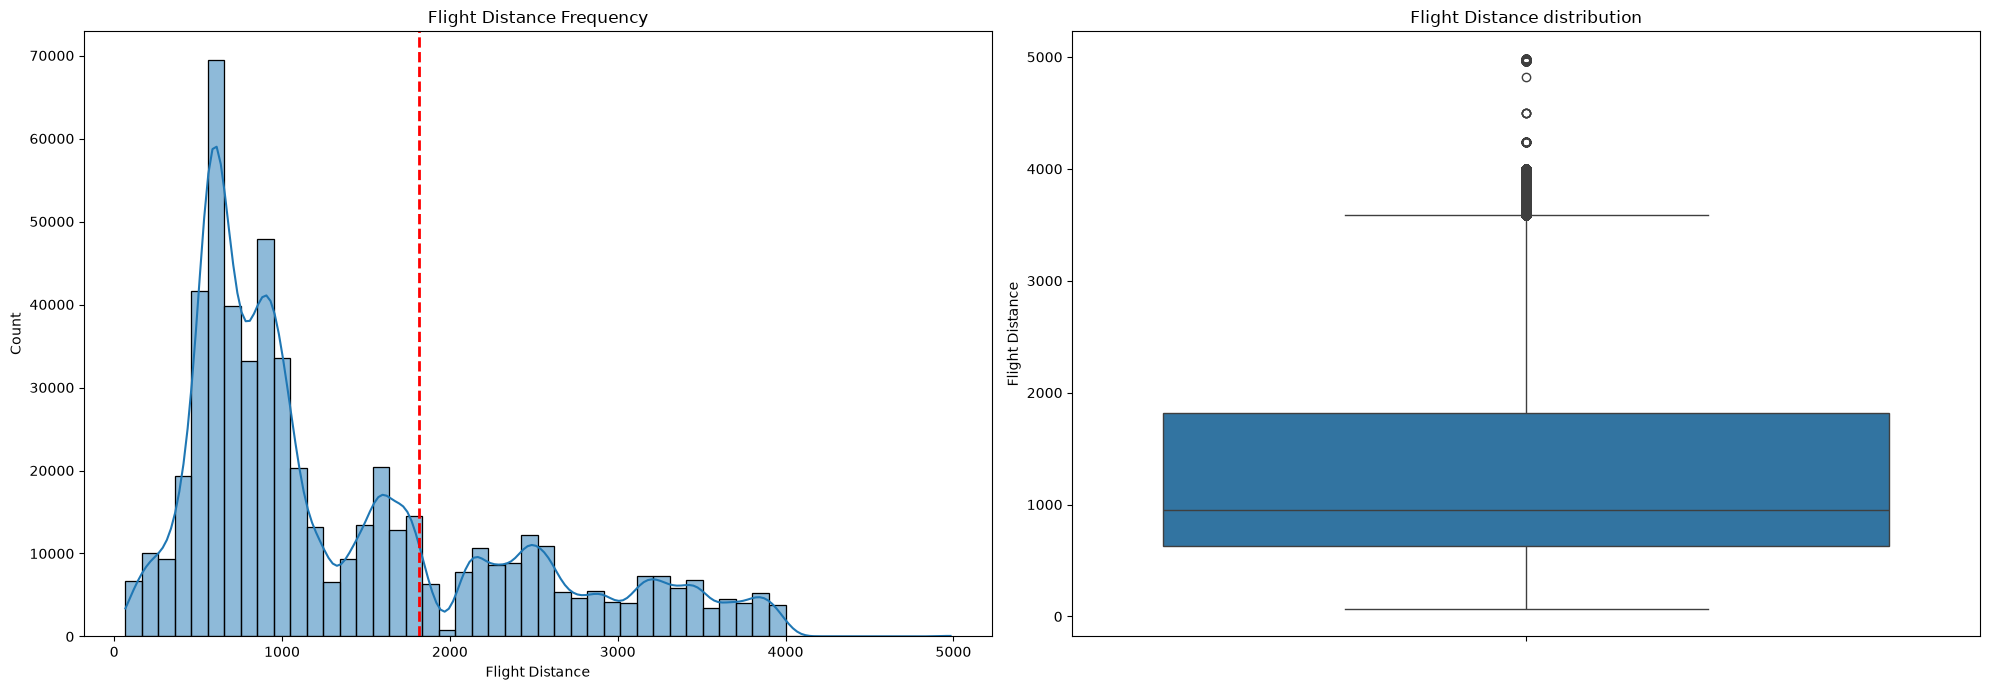

In [11]:
Q1 = df['Flight Distance'].quantile(0.25)
Q3 = df['Flight Distance'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['Flight Distance'] < lower_bound) | (df['Flight Distance'] > upper_bound)]
print(f'Lower bound: {lower_bound}')
print(f'Upper bound: {upper_bound}')
print(f'Number of outliers: {len(outliers)}')

fig, ax = plt.subplots(1, 2, figsize=(20, 7))
sns.histplot(df['Flight Distance'], bins=50, kde=True, ax=ax[0])
ax[0].set_title('Flight Distance Frequency')
ax[0].axvline(x=df['Flight Distance'].quantile(0.75), color='red', linestyle='--', linewidth=2)
sns.boxplot(df['Flight Distance'], ax=ax[1])
ax[1].set_title('Flight Distance distribution')
plt.tight_layout()
plt.show()

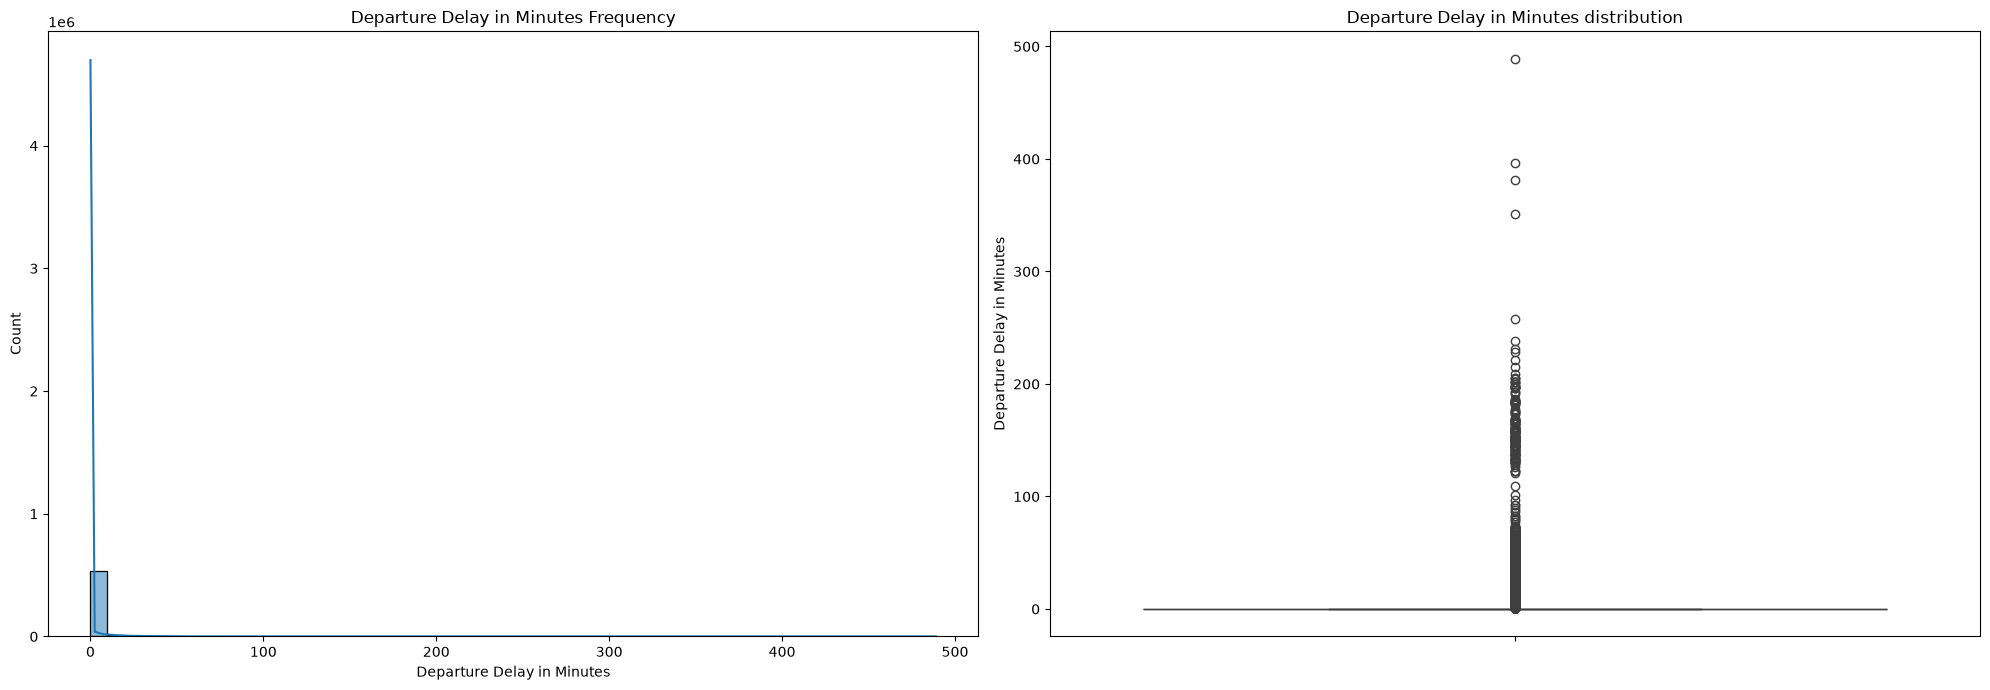

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(20, 7))
sns.histplot(df['Departure Delay in Minutes'], bins=50, kde=True, ax=ax[0])
ax[0].set_title('Departure Delay in Minutes Frequency')
sns.boxplot(df['Departure Delay in Minutes'], ax=ax[1])
ax[1].set_title('Departure Delay in Minutes distribution')
plt.tight_layout()
plt.show()

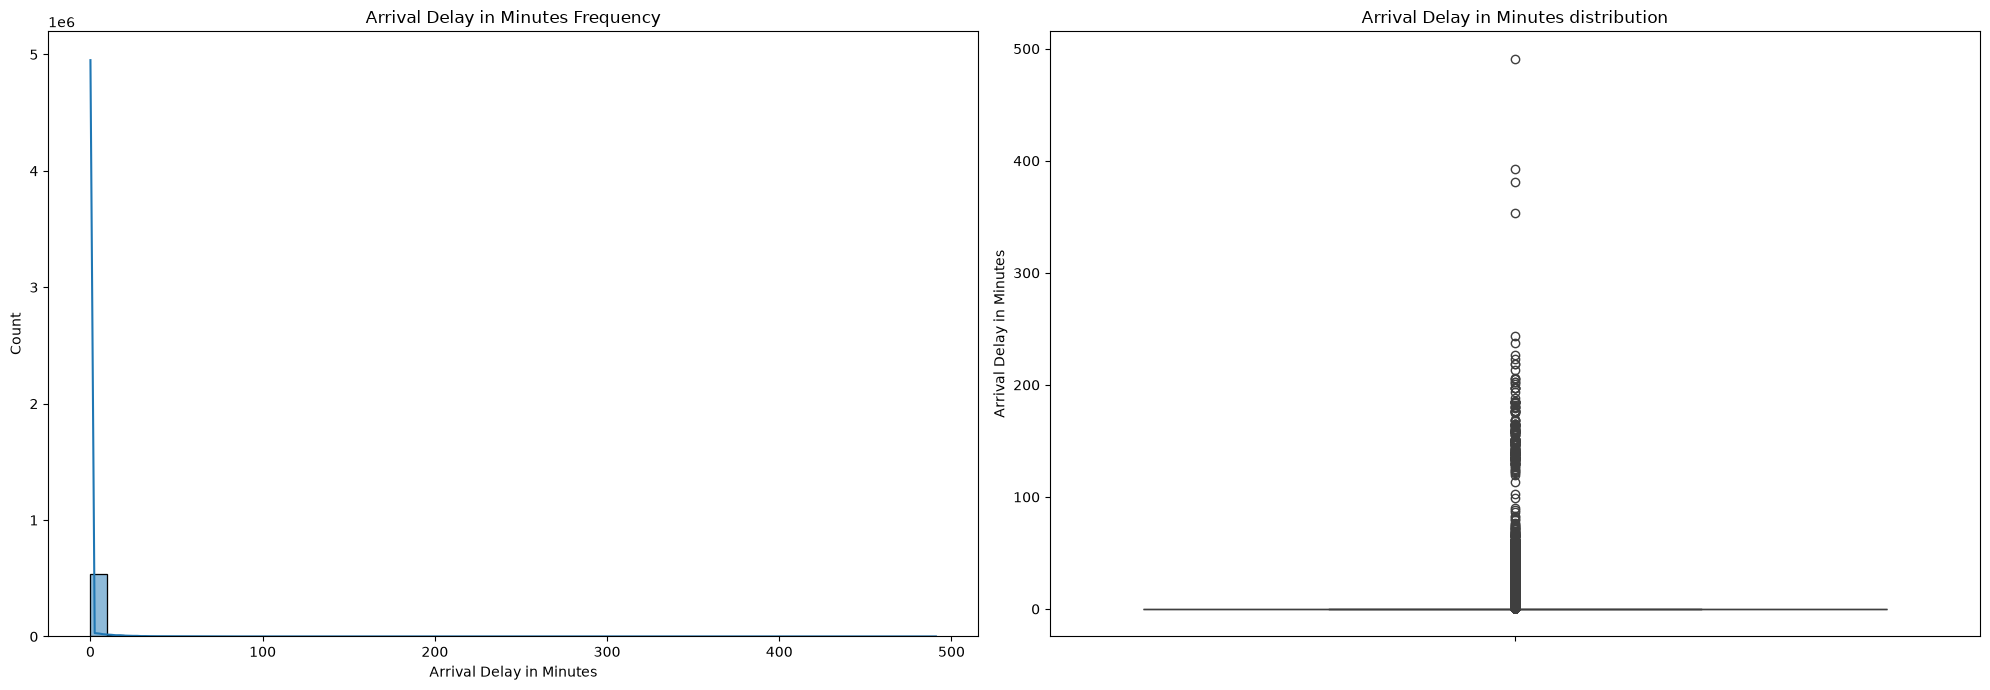

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(20, 7))
sns.histplot(df['Arrival Delay in Minutes'], bins=50, kde=True, ax=ax[0])
ax[0].set_title('Arrival Delay in Minutes Frequency')
sns.boxplot(df['Arrival Delay in Minutes'], ax=ax[1])
ax[1].set_title('Arrival Delay in Minutes distribution')
plt.tight_layout()
plt.show()

In [14]:
from IPython.display import display

categorical_columns = [
    'Inflight wifi service',
    'Departure/Arrival time convenient',
    'Ease of Online booking',
    'Gate location',
    'Food and drink',
    'Online boarding',
    'Seat comfort',
    'Inflight entertainment',
    'On-board service',
    'Leg room service',
    'Baggage handling',
    'Checkin service',
    'Cleanliness',
    'Gender',
    'Customer Type',
    'Type of Travel',
    'Class',
    'satisfaction'
]

for col in categorical_columns:
    print(f'{col} (unique values: {len(df[col].unique())})')
    display(df[col].unique())

Inflight wifi service (unique values: 6)


array([1, 4, 2, 3, 5, 0])

Departure/Arrival time convenient (unique values: 6)


array([1, 2, 3, 4, 5, 0])

Ease of Online booking (unique values: 6)


...

<StringArray>
['Business travel', 'Personal Travel']
Length: 2, dtype: str

Class (unique values: 3)


<StringArray>
['Business', 'Eco', 'Eco Plus']
Length: 3, dtype: str

satisfaction (unique values: 2)


array([ True, False])

## Numerical Categorical value Analysis:
Let's look at features the numerical categorical features, that might provide a sognifcant information about the customer's satisfaction.
This data looks like a rating on the serivces provided by the flight agencies.

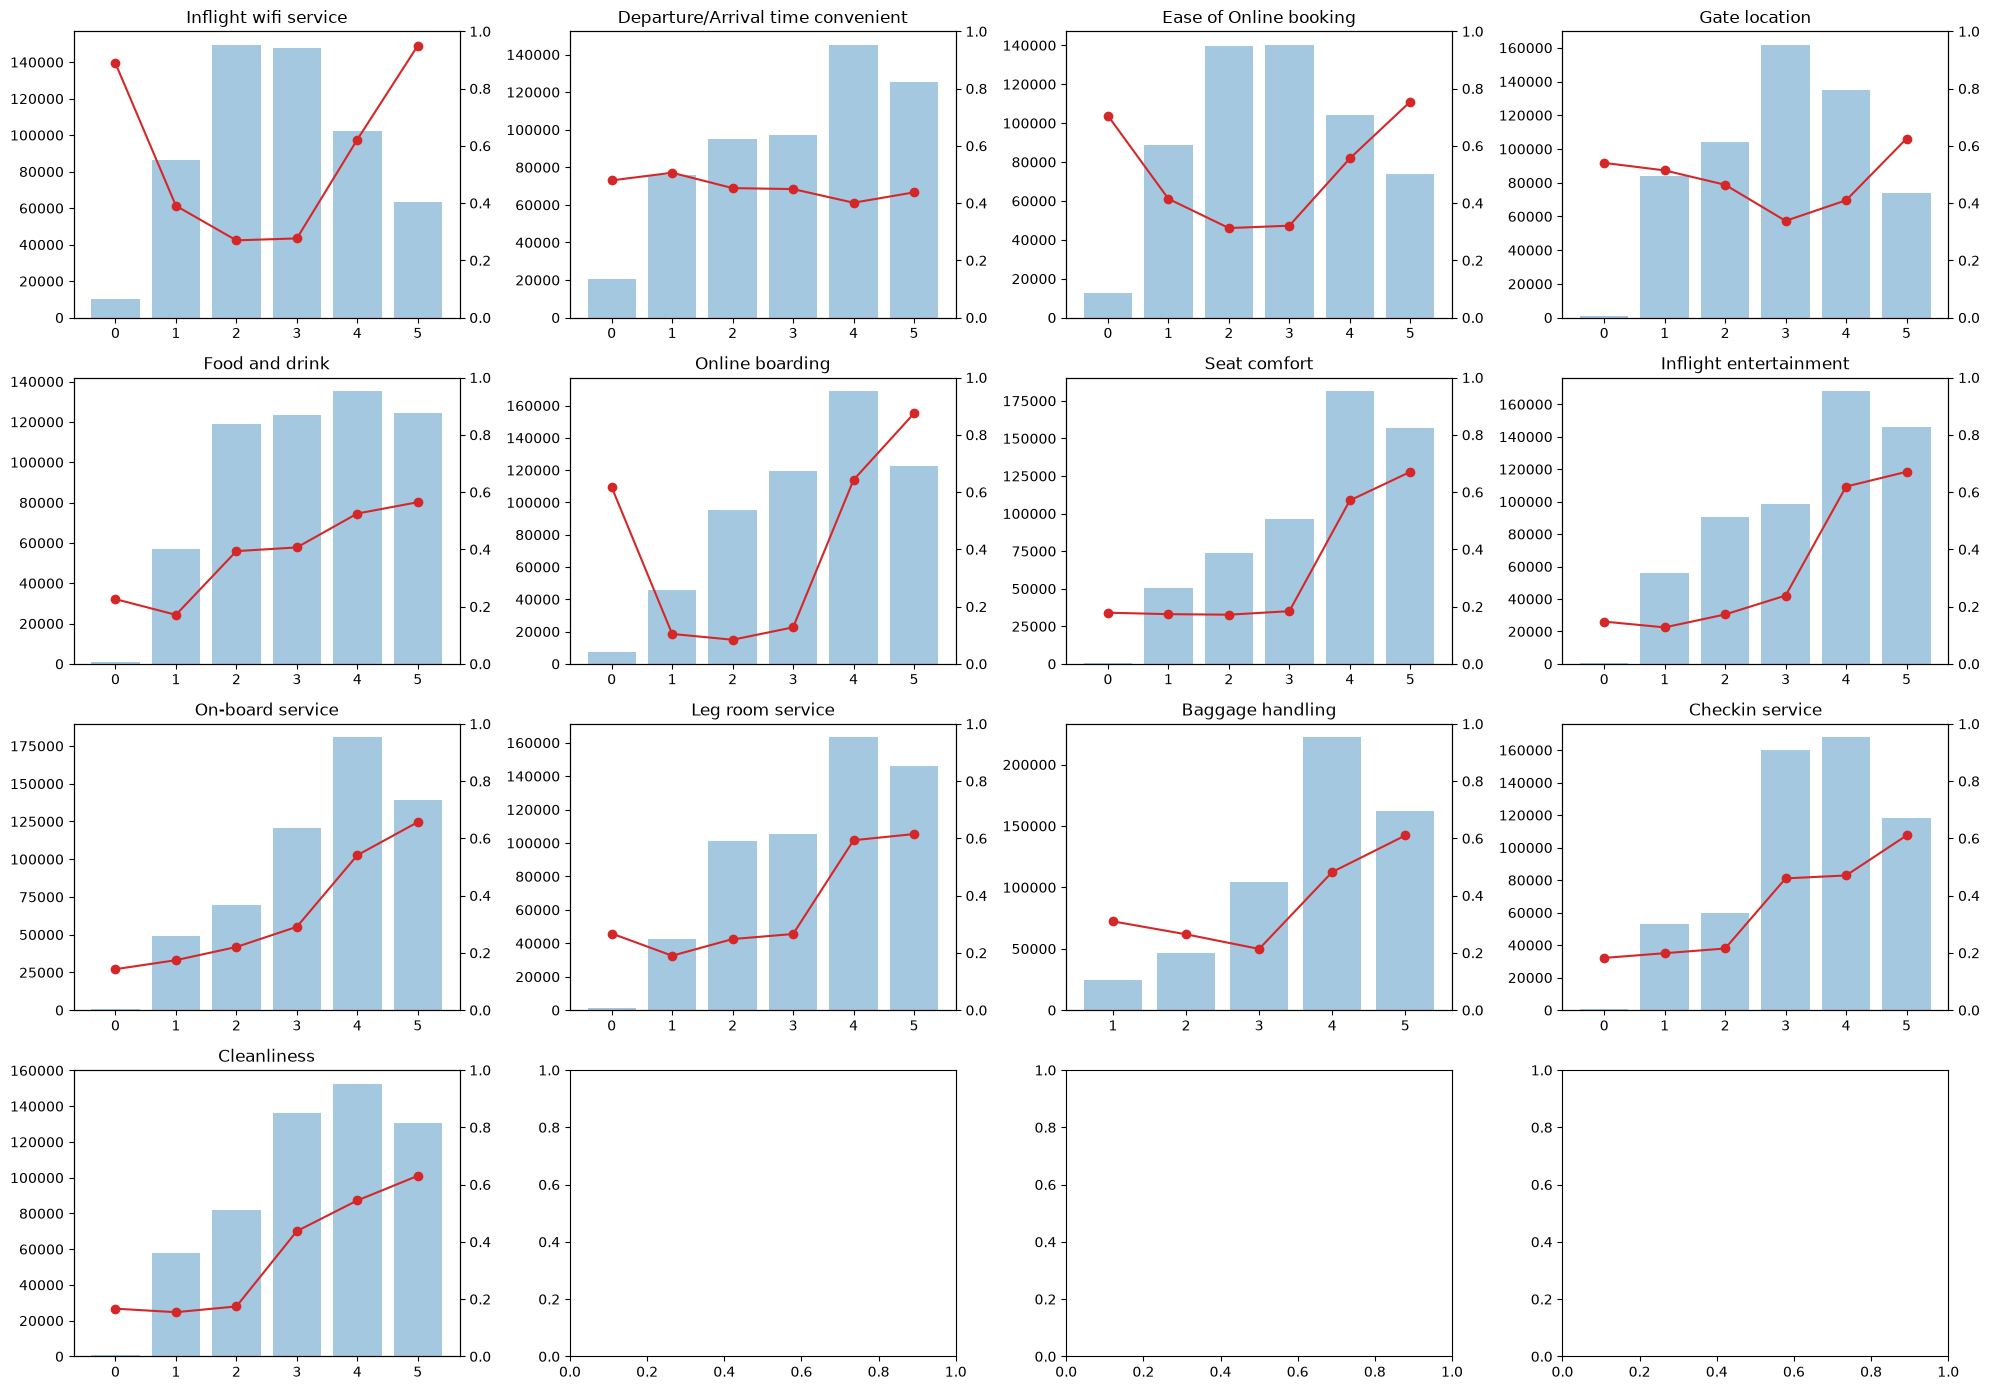

In [15]:
rating_cols = [
    'Inflight wifi service',
    'Departure/Arrival time convenient',
    'Ease of Online booking',
    'Gate location',
    'Food and drink',
    'Online boarding',
    'Seat comfort',
    'Inflight entertainment',
    'On-board service',
    'Leg room service',
    'Baggage handling',
    'Checkin service',
    'Cleanliness',
]

fig, axes = plt.subplots(4, 4, figsize=(20, 14))
for ax, c in zip(axes.flat, rating_cols):
    counts = df[c].value_counts().sort_index()
    rate = df.groupby(c)['satisfaction'].mean()
    ax.bar(counts.index, counts.values, alpha=0.4)
    ax2 = ax.twinx()
    ax2.plot(rate.index, rate.values, marker='o', color='C3')
    ax2.set_ylim(0, 1)
    ax.set_title(c)
plt.tight_layout()
plt.show()

In [16]:
zero_flags = (df[rating_cols] == 0)

# 1) most common zero patterns
pattern = zero_flags.loc[zero_flags.any(axis=1)].apply(
    lambda r: ' + '.join(r.index[r]), axis=1)
print(pattern.value_counts().head(10))

# 2) satisfaction rate and size by number of zeros
n_zero = zero_flags.sum(axis=1)
print(df.groupby(n_zero)['satisfaction'].agg(['mean', 'size']))

# 3) who has zeros? (check travel type and customer type)
online3 = ['Inflight wifi service', 'Ease of Online booking', 'Online boarding']
any_online0 = zero_flags[online3].any(axis=1)
for c in ['Type of Travel', 'Customer Type', 'Class']:
    print(df.groupby(c)['satisfaction'].agg(['mean']).join(
        any_online0.groupby(df[c]).mean().rename('online_zero_rate')))

Departure/Arrival time convenient                                                                       14359
Inflight wifi service + Departure/Arrival time convenient + Ease of Online booking                       2594
Inflight wifi service + Departure/Arrival time convenient + Ease of Online booking + Online boarding     2205
Inflight wifi service + Ease of Online booking + Online boarding                                         2053
Ease of Online booking + Online boarding                                                                 1717
Inflight wifi service                                                                                    1579
Inflight wifi service + Ease of Online booking                                                           1372
Ease of Online booking                                                                                   1316
Gate location                                                                                            1063
Inflight e

Zero ratings. 94% of rows have no zeros. Zeros are concentrated in Departure/Arrival time, Ease of Online booking, Wifi and Online boarding. They co-occur (more rows with 3 zeros than with 2) and don’t depend much on Class. In wifi, booking and boarding the 0 group has a high satisfaction rate, so 0 looks like “not applicable / not rated” rather than the worst score. Treat 0 as its own category (flag it) instead of the bottom of the 1-5 scale.

Zero ratings are structured. The wifi, online booking and online boarding ratings go to 0 together, and Departure/Arrival time is usually zero on its own. Rows with 3+ zeros are 86-94% satisfied vs. 44% overall, while 1 zero is lower (32%). The zero rate is roughly flat across Class, Type of Travel and Customer Type, so it carries information of its own. Candidate features: n_zeros, online_zeros, dep_arr_zero, plus per-feature zero flags. Next: check the effect within each segment.

In [17]:
df['online_zeros'] = zero_flags[online3].sum(axis=1)

# 1) satisfaction by number of zeros among the 3 online features
print(df.groupby('online_zeros')['satisfaction'].agg(['mean', 'size']))

# 2) does the effect hold inside each segment?
print(df.pivot_table(index='Type of Travel', columns='online_zeros',
                     values='satisfaction', aggfunc='mean').round(3))
print(df.pivot_table(index='Class', columns='online_zeros',
                     values='satisfaction', aggfunc='mean').round(3))

# 3) candidate features
df['dep_arr_zero'] = zero_flags['Departure/Arrival time convenient'].astype(int)
df['n_zeros'] = zero_flags.sum(axis=1)

                  mean    size
online_zeros                  
0             0.437282  544317
1             0.395889    4524
2             0.662687    6534
3             0.953150    4333
online_zeros         0      1      2      3
Type of Travel                             
Business travel  0.578  0.559  0.857  0.952
Personal Travel  0.088  0.118  0.231  0.957
online_zeros      0      1      2      3
Class                                   
Business      0.721  0.690  0.923  0.949
Eco           0.160  0.151  0.216  0.955
Eco Plus      0.232  0.157  0.265  0.960


Online-rating zeros are a strong, segment-independent signal. When wifi, online booking and online boarding are all 0, satisfaction is ~95% in every Class and Type of Travel (vs. 9-72% baseline by segment). Two zeros gives a partial lift (66% overall) and a single zero is roughly baseline. Add online_zeros (as a category), an online_all_zero flag and dep_arr_zero.

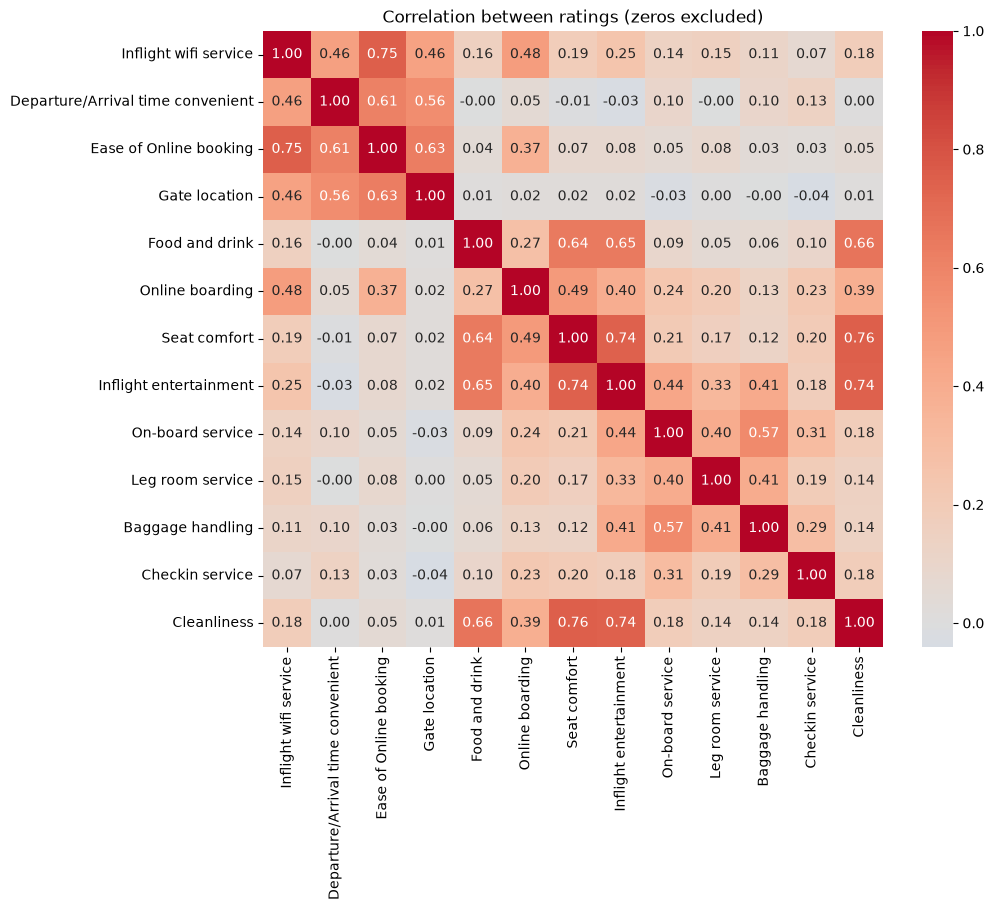

In [18]:
r = df.loc[(df[rating_cols] > 0).all(axis=1), rating_cols]
plt.figure(figsize=(10, 8))
sns.heatmap(r.corr(method='pearson'), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation between ratings (zeros excluded)')
plt.show()

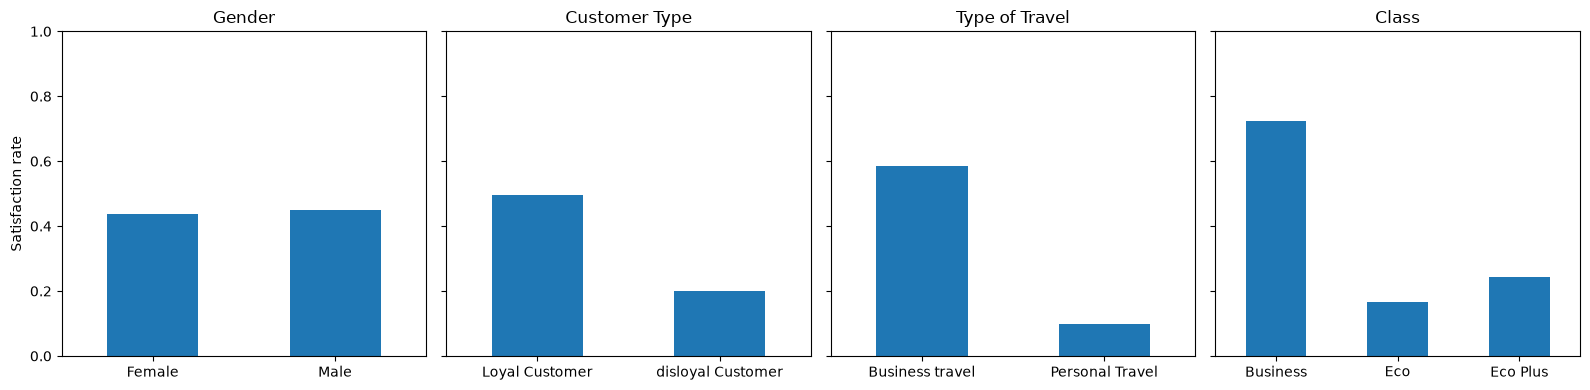

In [19]:
nominal_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, c in zip(axes, nominal_cols):
    df.groupby(c)['satisfaction'].mean().plot.bar(ax=ax, rot=0)
    ax.set_title(c); ax.set_ylim(0, 1); ax.set_xlabel('')
axes[0].set_ylabel('Satisfaction rate')
plt.tight_layout()
plt.show()

### Nominal features

Gender, Customer Type, Type of Travel and Class are treated as nominal.

- **Gender:** satisfaction is almost identical for both groups (~44% vs. ~45%), so it carries essentially no signal. It will be encoded as a single binary column (or dropped).
- **Customer Type:** loyal customers are more satisfied than disloyal ones (~50% vs. ~20%).
- **Type of Travel:** business travel (~58%) is far above personal travel (~10%), making it one of the strongest features.
- **Class:** Business (~73%) is well above Eco Plus (~24%) and Eco (~17%), which also makes it one of the strongest features.

**Encoding:** one-hot with `drop_first=True` (5 columns in total), reusing the training columns for the holdout and test sets.

## Modeling Pipeline Steps


In [20]:
cat_cols=['Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness', 'Gender',
       'Customer Type', 'Type of Travel', 'Class']

num_cols=[ 'Age', 'Flight Distance','Departure Delay in Minutes', 'Arrival Delay in Minutes']

In [21]:
null_df=df[df['Arrival Delay in Minutes'].isnull()]

In [22]:
null_df

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction,online_zeros,dep_arr_zero,n_zeros
437310,437310,23,762,4,4,4,4,3,4,3,3,3,5,4,3,3,10,NaN,Male,disloyal Customer,Business travel,Eco,True,0,0,0
243124,243124,30,1471,4,4,4,4,5,5,5,5,3,3,4,5,5,0,NaN,Female,Loyal Customer,Business travel,Business,True,0,0,0
407939,407939,46,1258,4,4,4,4,5,3,4,5,5,5,5,5,5,0,NaN,Female,Loyal Customer,Business travel,Business,True,0,0,0
673931,673931,39,447,3,2,2,2,3,3,3,3,2,5,4,3,3,0,NaN,Female,disloyal Customer,Business travel,Business,False,0,0,0
469497,469497,43,1628,2,2,2,2,5,4,4,2,2,2,2,2,4,0,NaN,Male,Loyal Customer,Business travel,Business,False,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49147,49147,39,759,4,4,4,4,3,4,3,3,4,4,5,4,3,0,NaN,Male,Loyal Customer,Personal Travel,Eco,False,0,0,0
92446,92446,32,3546,3,3,3,3,4,4,4,4,2,3,5,4,4,202,NaN,Female,Loyal Customer,Business travel,Business,True,0,0,0
133105,133105,27,1262,2,2,2,3,2,2,2,2,3,5,4,4,2,0,NaN,Female,disloyal Customer,Business travel,Business,False,0,0,0
383797,383797,25,1739,1,4,1,2,2,1,2,2,4,5,5,5,2,0,NaN,Female,Loyal Customer,Personal Travel,Eco,False,0,0,0


In [23]:
null_df.groupby('Departure Delay in Minutes')['Flight Distance'].min()

Departure Delay in Minutes
0       190
1       937
2       919
3       562
4       552
5       758
6       679
8       919
10      762
11      399
13     2521
14     3137
15      370
16      397
17      447
19     2559
20     1582
22      874
23      731
26     1678
27      369
28      919
30      925
31      157
36     2475
38      646
42      106
45      859
46      705
51     1023
63     1090
72      602
86     1437
92     2525
151     694
191    1605
202    3546
Name: Flight Distance, dtype: int64

In [24]:
test_data=pd.read_csv(path+"/test.csv")

## MLP preprocessing (v2)
Age bands (one-hot), arrival delay = departure + median train gap, `log1p` + scale for distance/delays, ratings kept ordinal (0 = not rated -> neutral fill + flags), Class ordinal. Zero features are tested by ablation.

In [25]:
# Does distance matter? Satisfaction rate by distance decile, split by Type of Travel.
tmp = X_train.assign(satisfaction=y_train, dist_decile=pd.qcut(X_train['Flight Distance'], 10, duplicates='drop'))
print(tmp.pivot_table(index='dist_decile', columns='Type of Travel', values='satisfaction', aggfunc='mean').round(3))


Type of Travel    Business travel  Personal Travel
dist_decile                                       
(66.999, 508.0]             0.439            0.112
(508.0, 591.0]              0.457            0.091
(591.0, 680.0]              0.447            0.083
(680.0, 842.0]              0.426            0.102
(842.0, 954.0]              0.418            0.096
(954.0, 1189.0]             0.408            0.093
(1189.0, 1620.0]            0.621            0.104
(1620.0, 2239.0]            0.743            0.109
(2239.0, 2933.0]            0.758            0.101
(2933.0, 4983.0]            0.799            0.087


In [26]:
# MLP v2: preprocessing redesigned for a neural net (all stats learned on TRAIN only, via fit()).
import numpy as np, pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neural_network import MLPClassifier

RATING_COLS = ['Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
               'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment',
               'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness']
ONLINE_COLS = ['Inflight wifi service', 'Ease of Online booking', 'Online boarding']
AGE_BINS = [0, 20, 30, 40, 50, 60, 70, np.inf]          # from the EDA: peaks ~25 & ~39, cliff at 60, tiny 70+ tail
DIST_BINS = [0, 500, 1200, 2000, np.inf]      # short / regional / medium / long haul (EDA peaks ~600, ~900, ~1700, ~2500)
DIST_LABELS = ['<500', '500-1199', '1200-1999', '2000+']
AGE_LABELS = ['<20', '20-29', '30-39', '40-49', '50-60', '61-70', '70+']
BIN_COLS = ['Gender', 'Customer Type', 'Type of Travel']
ORD_MAP = {'Gender': {'Male': 0, 'Female': 1},
           'Customer Type': {'disloyal Customer': 0, 'Loyal Customer': 1},
           'Type of Travel': {'Personal Travel': 0, 'Business travel': 1},   # binary == trivially ordinal
           'Class': {'Eco': 0, 'Eco Plus': 1, 'Business': 2}}                # true order


class FlightFeatures(BaseEstimator, TransformerMixin):
    """Row-wise feature engineering + the delay-gap imputation (the only learned state: the median gap)."""
    def __init__(self, use_zero_feats=True, use_dist_bands=True):
        self.use_zero_feats = use_zero_feats
        self.use_dist_bands = use_dist_bands

    def fit(self, X, y=None):
        gap = (X['Arrival Delay in Minutes'] - X['Departure Delay in Minutes']).dropna()
        self.median_gap_ = float(gap.median())
        # per-column 'typical rating' used to fill the 0 = not-rated cells so the 1-5 scale isn't distorted
        self.rating_fill_ = {c: float(X.loc[X[c] > 0, c].median()) for c in RATING_COLS}
        return self

    def transform(self, X):
        d = X.drop(columns=['id'], errors='ignore').copy()
        # 1) Arrival delay NaN -> departure delay + median(arrival - departure) from train
        miss = d['Arrival Delay in Minutes'].isna()
        d.loc[miss, 'Arrival Delay in Minutes'] = d.loc[miss, 'Departure Delay in Minutes'] + self.median_gap_
        d['Arrival Delay in Minutes'] = d['Arrival Delay in Minutes'].clip(lower=0)
        # 2a) distance bands (computed on the raw value, BEFORE the log); the continuous log distance is kept too
        if self.use_dist_bands:
            d['dist_band'] = pd.cut(d['Flight Distance'], DIST_BINS, labels=DIST_LABELS, right=False).astype(str)
        # 2b) skew fixes: log1p (zero-safe) before scaling
        for c in ['Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']:
            d[c] = np.log1p(d[c])
        # 3) age -> bands (one-hot later)
        d['age_band'] = pd.cut(d['Age'], AGE_BINS, labels=AGE_LABELS, right=False).astype(str)
        d = d.drop(columns='Age')
        # 4) ordinal / binary maps
        for c, m in ORD_MAP.items():
            d[c] = d[c].map(m).astype('float64')
        # 5) zero-rating features, then neutralise the zeros inside the rating columns
        if self.use_zero_feats:
            z = d[RATING_COLS].eq(0)
            d['online_zeros'] = z[ONLINE_COLS].sum(axis=1).astype(str)       # 0..3, non-monotonic -> categorical
            d['dep_arr_zero'] = z['Departure/Arrival time convenient'].astype('float64')
        for c in RATING_COLS:
            d[c] = d[c].where(d[c] > 0, self.rating_fill_[c]).astype('float64')
        return d


def make_mlp_pipeline(use_zero_feats=True, use_dist_bands=True, **mlp_kw):
    cat = ['age_band'] + (['dist_band'] if use_dist_bands else []) + (['online_zeros'] if use_zero_feats else [])
    scale = ['Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes'] + RATING_COLS + ['Class']
    passthru = BIN_COLS + (['dep_arr_zero'] if use_zero_feats else [])
    ct = ColumnTransformer([
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat),
        ('scale', StandardScaler(), scale),
        ('bin', 'passthrough', passthru)])
    params = dict(hidden_layer_sizes=(64, 32), alpha=1e-5, batch_size=2048, learning_rate_init=1e-3,
                  max_iter=60, early_stopping=True, validation_fraction=0.1, n_iter_no_change=5, random_state=42)
    params.update(mlp_kw)
    return Pipeline([('features', FlightFeatures(use_zero_feats, use_dist_bands)), ('prep', ct), ('model', MLPClassifier(**params))])


In [27]:
# Ablation: same split, same MLP settings; only the preprocessing differs.
import warnings; warnings.filterwarnings('ignore')
from sklearn.metrics import roc_auc_score, log_loss

OLD_MLP_HOLDOUT_AUC = 0.9561   # old one-hot MLP, from the earlier run
variants = {'v2 full (zero feats + dist bands)': (True, True),
            'v2, no distance bands':             (True, False),
            'v2, no zero features':              (False, True)}
rows = []
for name, (zf, db) in variants.items():
    p = make_mlp_pipeline(zf, db).fit(X_train, y_train)
    pr = p.predict_proba(X_test)[:, 1]
    rows.append({'variant': name, 'n_features': p[:-1].transform(X_test.head(5)).shape[1],
                 'holdout_auc': roc_auc_score(y_test, pr), 'holdout_logloss': log_loss(y_test, pr)})
rows.append({'variant': 'old MLP (reference)', 'n_features': None, 'holdout_auc': OLD_MLP_HOLDOUT_AUC, 'holdout_logloss': 0.2357})
ablation = pd.DataFrame(rows); ablation.round(4)


,variant,n_features,holdout_auc,holdout_logloss
0,v2 full (zero feats + dist bands),36.0,0.9556,0.2358
1,"v2, no distance bands",32.0,0.9559,0.2353
2,"v2, no zero features",31.0,0.9545,0.2414
3,old MLP (reference),NaN,0.9561,0.2357


In [28]:
# Tune the MLP (same grid as before) with the better variant, then refit-score on holdout.
from sklearn.model_selection import RandomizedSearchCV
best_zero, best_dist = list(variants.values())[ablation.iloc[:3]['holdout_auc'].values.argmax()]
mlp_search = RandomizedSearchCV(
    make_mlp_pipeline(best_zero, best_dist),
    param_distributions={'model__hidden_layer_sizes': [(32,), (64,), (64, 32)],
                         'model__alpha': [1e-5, 1e-4, 1e-3],
                         'model__learning_rate_init': [1e-4, 3e-4, 1e-3]},
    n_iter=4, cv=3, scoring='roc_auc', n_jobs=1, random_state=42, verbose=1)
mlp_search.fit(X_train, y_train)
best_model = mlp_search.best_estimator_
print('Best params:', mlp_search.best_params_)
print(f'CV AUC {mlp_search.best_score_:.4f} | holdout AUC {roc_auc_score(y_test, best_model.predict_proba(X_test)[:, 1]):.4f}')


Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best params: {'model__learning_rate_init': 0.001, 'model__hidden_layer_sizes': (64, 32), 'model__alpha': 1e-05}
CV AUC 0.9561 | holdout AUC 0.9559


## Boosted models + soft-voting blend
Trees get raw ordinals plus interaction features (segment crossings, rating mean/min, zero counts). Early stopping uses an inner split of train, never the holdout.

In [29]:
# Tree-model features: raw ordinals (no scaling/binning), NaN kept for arrival-delay-free handling, plus interactions.
from sklearn.model_selection import train_test_split

def tree_frame(X, median_gap):
    d = X.drop(columns=['id'], errors='ignore').copy()
    miss = d['Arrival Delay in Minutes'].isna()
    d.loc[miss, 'Arrival Delay in Minutes'] = d.loc[miss, 'Departure Delay in Minutes'] + median_gap
    for c, m in ORD_MAP.items():
        d[c] = d[c].map(m).astype('int8')
    z = d[RATING_COLS].eq(0)
    d['online_zeros'] = z[ONLINE_COLS].sum(axis=1)
    d['dep_arr_zero'] = z['Departure/Arrival time convenient'].astype('int8')
    d['n_zeros'] = z.sum(axis=1)
    rated = d[RATING_COLS].where(~z)
    d['rating_mean'] = rated.mean(axis=1)
    d['rating_min'] = rated.min(axis=1)
    d['travel_x_class'] = d['Type of Travel'] * 3 + d['Class']          # 6 segments
    d['loyal_x_travel'] = d['Customer Type'] * 2 + d['Type of Travel']  # 4 segments
    return d

median_gap = float((X_train['Arrival Delay in Minutes'] - X_train['Departure Delay in Minutes']).dropna().median())
T_train, T_test, T_final = (tree_frame(f, median_gap) for f in (X_train, X_test, test_data))
# inner validation split (from TRAIN only) for early stopping, so the holdout stays untouched
T_fit, T_val, y_fit, y_val = train_test_split(T_train, y_train, test_size=0.1, stratify=y_train, random_state=0)
print(T_train.shape)


(559708, 28)


In [30]:
# Tuned boosted models with early stopping. SMOKE=True only for a quick dry run.
import lightgbm as lgb, itertools, random
from catboost import CatBoostClassifier
SMOKE = False
rng = random.Random(42)

# --- LightGBM: small random search, scored on the inner validation split ---
best = (0, None, None)
for _ in range(2 if SMOKE else 12):
    p = dict(learning_rate=0.05, num_leaves=rng.choice([31, 63, 127, 255]),
             min_child_samples=rng.choice([20, 50, 100]), colsample_bytree=rng.choice([0.5, 0.7, 0.9]),
             subsample=rng.choice([0.7, 0.9]), subsample_freq=1, reg_lambda=rng.choice([0, 1, 5, 10]),
             n_estimators=50 if SMOKE else 4000, random_state=42, verbose=-1)
    m = lgb.LGBMClassifier(**p).fit(T_fit, y_fit, eval_set=[(T_val, y_val)], eval_metric='auc',
                                   callbacks=[lgb.early_stopping(100, verbose=False)])
    s = roc_auc_score(y_val, m.predict_proba(T_val)[:, 1])
    print(f'LGBM val AUC {s:.4f}  iters {m.best_iteration_}  leaves {p["num_leaves"]}')
    if s > best[0]: best = (s, p, m.best_iteration_)
lgb_params, lgb_iters = best[1], best[2]
lgb_model = lgb.LGBMClassifier(**{**lgb_params, 'n_estimators': lgb_iters}).fit(T_train, y_train)  # refit on all train

# --- CatBoost ---
cat_model = CatBoostClassifier(iterations=30 if SMOKE else 4000, learning_rate=0.08, depth=8, eval_metric='AUC',
                               od_type='Iter', od_wait=100, random_seed=42, verbose=500, thread_count=-1)
cat_model.fit(T_fit, y_fit, eval_set=(T_val, y_val), use_best_model=True)

for name, m in [('LightGBM', lgb_model), ('CatBoost', cat_model)]:
    print(name, 'holdout AUC', round(roc_auc_score(y_test, m.predict_proba(T_test)[:, 1]), 4))


LGBM val AUC 0.9583  iters 524  leaves 31
LGBM val AUC 0.9583  iters 299  leaves 63
LGBM val AUC 0.9589  iters 215  leaves 255
LGBM val AUC 0.9585  iters 339  leaves 63
LGBM val AUC 0.9584  iters 161  leaves 255
LGBM val AUC 0.9588  iters 482  leaves 63
LGBM val AUC 0.9585  iters 262  leaves 63
LGBM val AUC 0.9588  iters 220  leaves 255
LGBM val AUC 0.9586  iters 512  leaves 31
LGBM val AUC 0.9584  iters 484  leaves 31
LGBM val AUC 0.9584  iters 955  leaves 31
LGBM val AUC 0.9588  iters 889  leaves 31
0:	test: 0.9470226	best: 0.9470226 (0)	total: 111ms	remaining: 7m 24s
500:	test: 0.9583439	best: 0.9583439 (500)	total: 11.9s	remaining: 1m 22s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.9584237145
bestIteration = 691

Shrink model to first 692 iterations.
LightGBM holdout AUC 0.958
CatBoost holdout AUC 0.9576


In [31]:
# Soft-voting diagnostic: holdout probabilities from each model, their correlation, then blends.
from scipy.stats import rankdata

P = {'LightGBM': lgb_model.predict_proba(T_test)[:, 1], 'CatBoost': cat_model.predict_proba(T_test)[:, 1]}
mlp_seeds = [make_mlp_pipeline(best_zero, best_dist, random_state=s).fit(X_train, y_train) for s in (1, 2, 3)]
P['MLP (3 seeds)'] = np.mean([m.predict_proba(X_test)[:, 1] for m in mlp_seeds], axis=0)

P_df = pd.DataFrame(P)
print('Holdout AUC per model:'); print(P_df.apply(lambda c: roc_auc_score(y_test, c)).round(4))
print('\nPrediction correlation (Spearman):'); print(P_df.corr(method='spearman').round(3))

rank = lambda a: rankdata(a) / len(a)
blends = {
    'GBDT only (LGBM+Cat)': P_df[['LightGBM', 'CatBoost']].mean(axis=1),
    'All three, equal': P_df.mean(axis=1),
    'All three, rank-avg': P_df.apply(rank).mean(axis=1),
}
print('\nBlends:'); print(pd.Series({k: roc_auc_score(y_test, v) for k, v in blends.items()}).round(4))


Holdout AUC per model:
LightGBM         0.9580
CatBoost         0.9576
MLP (3 seeds)    0.9559
dtype: float64

Prediction correlation (Spearman):
               LightGBM  CatBoost  MLP (3 seeds)
LightGBM          1.000     0.970          0.943
CatBoost          0.970     1.000          0.945
MLP (3 seeds)     0.943     0.945          1.000

Blends:
GBDT only (LGBM+Cat)    0.9581
All three, equal        0.9578
All three, rank-avg     0.9579
dtype: float64


In [32]:
# Submission: choose a blend from the table above (edit `chosen`). Rank-average of all three is the default.
from pathlib import Path
chosen = ['LightGBM', 'CatBoost', 'MLP']
final = {'LightGBM': lgb_model.predict_proba(T_final)[:, 1],
         'CatBoost': cat_model.predict_proba(T_final)[:, 1],
         'MLP': np.mean([m.predict_proba(test_data)[:, 1] for m in mlp_seeds], axis=0)}
blend = np.mean([rank(final[k]) for k in chosen], axis=0)   # rank-average -> values in (0, 1]
out = test_data[['id']].copy(); out['satisfaction'] = blend
Path('./kaggle/working').mkdir(parents=True, exist_ok=True)
out.to_csv('./kaggle/working/submission.csv', index=False)
print('Saved submission')


Saved submission
